In [3]:
import numpy as np
import matplotlib.pyplot as plt


Echauffement : le broadcasting

In [4]:
#question 1
a = np.array([1, 2, 3])
print(np.shape(a))
print(a)
a1=a[:, None] #on rajoute une dimension à a (les colonnes)
a2=a[None, :] #on rajoute une dimension (ligne)
print(np.shape(a1))
print(a1)
print(np.shape(a2))
print(a2)

(3,)
[1 2 3]
(3, 1)
[[1]
 [2]
 [3]]
(1, 3)
[[1 2 3]]


1. La forme de a[:, None] est [[1],[2],[3]] (matrice colonne) et de a[None, :] est [[1,2,3]] (matrice ligne).

In [5]:
#question 2
print(a[:, None] - a[None, :])
print(np.shape(a[:, None] - a[None, :]))

[[ 0 -1 -2]
 [ 1  0 -1]
 [ 2  1  0]]
(3, 3)


2. La forme de a[:, None] - a[None, :] est [[0,-1,-2],[1,0,-1],[2,1,0]] (une matrice carrée de dimension 3).

In [6]:
#question 3
b=np.arange(0,6).reshape(2,3)
print("b=",b)
print("b0=",b[:, None, :])
print("b1=",b[:, :, None])
print("bis=",b[:, None, :] - b[:, :, None])
print("dim_bis=",np.shape(b[:, None, :] - b[:, :, None]))

b= [[0 1 2]
 [3 4 5]]
b0= [[[0 1 2]]

 [[3 4 5]]]
b1= [[[0]
  [1]
  [2]]

 [[3]
  [4]
  [5]]]
bis= [[[ 0  1  2]
  [-1  0  1]
  [-2 -1  0]]

 [[ 0  1  2]
  [-1  0  1]
  [-2 -1  0]]]
dim_bis= (2, 3, 3)


3. La forme de b[:, None, :] - b[:, :, None] est [[[0,1,2],[-1,0,1],[-2,-1,0]],[[0,1,2],[-1,0,1],[-2,-1,0]]] qui est de dimension (2,3,3).

Initialisation aléatoire

In [7]:
# les bornes pour le tirage au sort initial
mass_max = 3.
    
x_min, x_max = -10., 10.
y_min, y_max = -10., 10.

speed_max = 1.

def init_problem(N):
    """
    retourne un tuple masses, positions, speeds
    de formes resp.   (N,)    (2, N)     (2, N)
    tiré au sort dans les bornes définies ci-dessus
    """
    masses=np.random.uniform(0.01,mass_max,size=N)
    #positions=np.zeros((2,N))
    #positions[0,:]=np.random.uniform(x_min,x_max)
    #positions[1,:]=np.random.uniform(y_min,y_max)
    positions=np.random.uniform(np.array([[x_min],[y_min]]),np.array([[x_max],[y_max]]),size=(2,N))
    speeds=np.random.uniform(-speed_max,speed_max,(2,N))
    return [masses,positions,speeds]

#verification
masses, positions, speeds = init_problem(10)
assert masses.shape == (10,) and positions.shape == speeds.shape == (2, 10)
print("OK")

OK


Initialisation reproductible

In [23]:
def init3():
    # first element is sun-like: heavy, at the center, and no speed
    masses = np.array([3, 1, 1], dtype=float)
    positions = np.array([
        [0, 5, -5], 
        [0, 1, -1]], dtype=float)
    speeds = np.array([
        [0, -1, 1], 
        [0, 0, 0]], dtype=float)
    return masses, positions, speeds

Les forces

In [9]:
def forces(masses, positions, G=1.0):
    """
    returns an array of shape (2,  N)
    that contains the force felt by each mass from all the others
    G is the Newton constant and by default is set to 1 
    (we have abstract units anyway)
    """
    diff = -positions[:,None,:]+positions[:,:,None]
    dist=np.linalg.norm(diff,axis=0)
    np.fill_diagonal(dist,np.inf) #car une particule n'interagit pas avec elle même
    pr_masses=np.multiply(masses[None,:],masses[:,None])
    force=G*pr_masses*diff/dist**3
    F=np.sum(force,axis=1)
    return F
    
masses, positions, speeds = init3()
f = forces(masses, positions)
f


array([[ 0.        , -0.12257258,  0.12257258],
       [ 0.        , -0.02451452,  0.02451452]])

Le simulateur

In [10]:
def simulate(masses, positions, speeds, dt=0.1, nb_steps=100):
    """
    should return the positions across time
    so an array of shape (nb_steps, 2, N)
    optional dt is the time step
    """
    tab=np.zeros((nb_steps,2,positions.shape[1]))
    tab[0]=positions
    for i in range (nb_steps):
        F=forces(masses, positions, G=1.0)
        acc=np.divide(F,masses[None,:])
        speeds=np.add(speeds,dt*acc)
        positions = np.add(positions, dt*speeds)
        tab[i]=positions

    return tab
    pass

# pour tester

SMALL_STEPS = 4

s = simulate(masses, positions, speeds, nb_steps=SMALL_STEPS)

try:
    if s.shape == (SMALL_STEPS, 2, 3):
        print("shape OK")
except Exception as exc:
    print(f"OOPS {type(exc)} {exc}")

shape OK


Dessiner

simulation[:, :, i] (de dimension (nb_steps,2)) correspond aux positions au cours du temps de la particule i. Sa transposée est de dimension (2,nb_steps).

In [32]:


def draw(simulation, masses, colors=None, scale=10.):
    """
    takes as input the result of simulate() above,
    and draws the nb_steps positions of each of the N bodies
    ideally it should return a matplotlib Axes object

    one can provide a collection of N colors to use for each body
    if not provided this is randomized

    also the optional scale parameter is used as a constant
    multiplier to obtain the final size of each dot on the figure
    """
    fig,ax=plt.subplots()
    for i in range(masses.shape[0]):
        X,Y=simulation[:,:,i].T[0],simulation[:,:,i].T[1]
        if colors is not None:
            plt.plot(X,Y, color=colors[i])
            ax.scatter(X[-1],Y[-1],s=30*masses[i], color=colors[i])
        else:
            plt.plot(X,Y)
            ax.scatter(X[-1],Y[-1],s=30*masses[i])

    plt.show()


    pass

In [33]:
colors3 = np.array([
    [32, 32, 32],
    (228, 90, 146),
    (111, 0, 255),
]) / 255

On assemble le tout

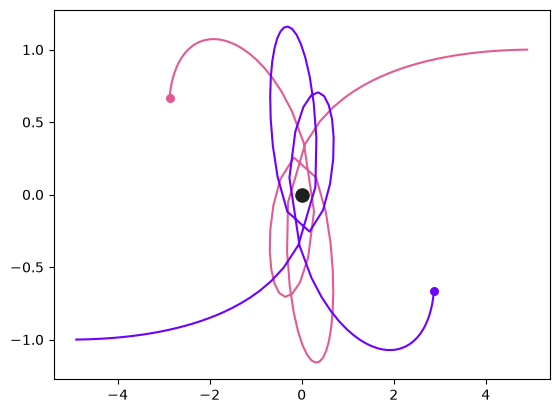

In [34]:
masses, positions, speeds = init3()
draw(simulate(masses, positions, speeds), masses, colors3)

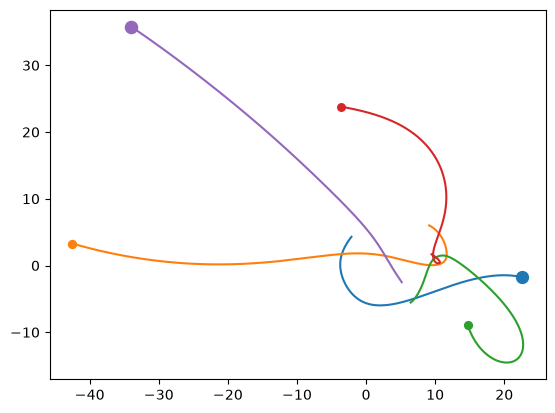

<Figure size 640x480 with 0 Axes>

In [31]:
#on s'enhardit
m5, p5, s5 = init_problem(5)
sim5 = simulate(m5, p5, s5, nb_steps=1000)
draw(sim5, m5, scale=3);
plt.savefig("random5.png")